In [1]:
import random, numpy as np, torch

SID4  = 2733
SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")

SID4=2733 SEED=2733 SLICE=733 HP_ID=3 CLS_A=3 CLS_B=7


In [2]:
!pip install transformers torch torchvision

In [3]:
import torch
from transformers import CLIPModel, CLIPProcessor


device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the pretrained CLIP model (image + text encoders) and its processor
model_name = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(model_name).to(device).eval()
processor = CLIPProcessor.from_pretrained(model_name)

print("Device:", device)
print("Embedding size:", model.config.projection_dim)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Device: cuda
Embedding size: 512


In [4]:
import numpy as np
from torchvision.datasets import CIFAR10


caption = "a photo of a dog"


test_set = CIFAR10(root="./data", train=False, download=True)
classes = test_set.classes
all_labels = np.array(test_set.targets)


n_per_class = 100
idx = np.concatenate([np.where(all_labels == c)[0][:n_per_class] for c in range(10)])

images = [test_set[i][0] for i in idx]
labels = all_labels[idx]

print("Classes:", classes)
print("Number of images:", len(images))
print("Images per class:", np.bincount(labels))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Number of images: 1000
Images per class: [100 100 100 100 100 100 100 100 100 100]


In [5]:
@torch.no_grad()
def get_image_embeddings(pil_images, batch_size=256):
    all_emb = []
    for i in range(0, len(pil_images), batch_size):
        batch = pil_images[i:i + batch_size]
        # PREPROCESS: resize to 224x224, normalize pixels, convert to a tensor
        inputs = processor(images=batch, return_tensors="pt").to(device)
        # EXTRACT: run the image encoder, which gives one 512-d vector per image
        emb = model.get_image_features(**inputs)
        if not torch.is_tensor(emb):        # newer transformers versions wrap the output
            emb = emb.pooler_output
        all_emb.append(emb)
    emb = torch.cat(all_emb)
    # NORMALIZE
    return emb / emb.norm(dim=-1, keepdim=True)

@torch.no_grad()
def get_text_embeddings(texts):
    inputs = processor(text=texts, return_tensors="pt", padding=True).to(device)
    emb = model.get_text_features(**inputs)
    if not torch.is_tensor(emb):
        emb = emb.pooler_output
    return emb / emb.norm(dim=-1, keepdim=True)

image_emb = get_image_embeddings(images)
caption_emb = get_text_embeddings([caption])

print("Image embeddings:", image_emb.shape)
print("Caption embedding:", caption_emb.shape)
print("Vector lengths (should be 1.0):", image_emb.norm(dim=-1)[:3], caption_emb.norm(dim=-1))

Image embeddings: torch.Size([1000, 512])
Caption embedding: torch.Size([1, 512])
Vector lengths (should be 1.0): tensor([1., 1., 1.], device='cuda:0') tensor([1.], device='cuda:0')


In [6]:
import pandas as pd


similarities = (image_emb @ caption_emb.T).squeeze(1).cpu().numpy()

print("Scores computed:", similarities.shape)
print("Range: min = %.3f, max = %.3f" % (similarities.min(), similarities.max()))

df = pd.DataFrame({"class": [classes[l] for l in labels], "similarity": similarities})
per_class = df.groupby("class")["similarity"].agg(["mean", "std", "min", "max"]).sort_values("mean", ascending=False)
print(f'\nSimilarity to "{caption}" by class:')
print(per_class.round(4))

# Classes of the 10 best-matching images
top10 = np.argsort(similarities)[::-1][:10]
print("\nClasses of the top 10 images:", [classes[labels[i]] for i in top10])

Scores computed: (1000,)
Range: min = 0.152, max = 0.285

Similarity to "a photo of a dog" by class:
              mean     std     min     max
class                                     
dog         0.2594  0.0120  0.2209  0.2855
cat         0.2394  0.0133  0.2057  0.2681
deer        0.2344  0.0137  0.2059  0.2743
frog        0.2291  0.0132  0.1941  0.2599
bird        0.2253  0.0133  0.1982  0.2751
horse       0.2201  0.0141  0.1920  0.2648
airplane    0.2035  0.0156  0.1521  0.2318
automobile  0.2015  0.0112  0.1726  0.2254
truck       0.1951  0.0100  0.1711  0.2228
ship        0.1951  0.0115  0.1691  0.2236

Classes of the top 10 images: ['dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'bird']


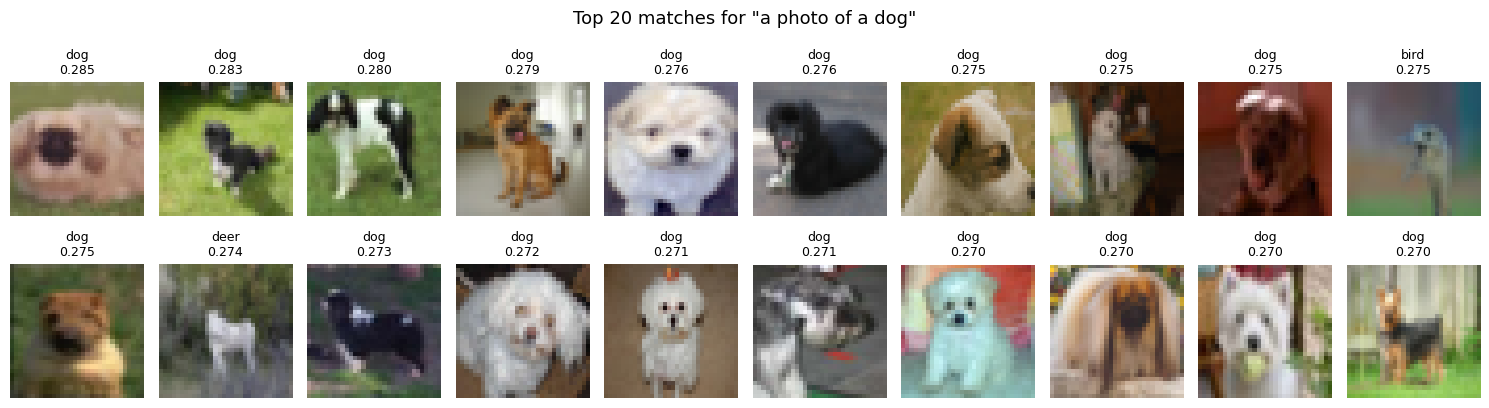

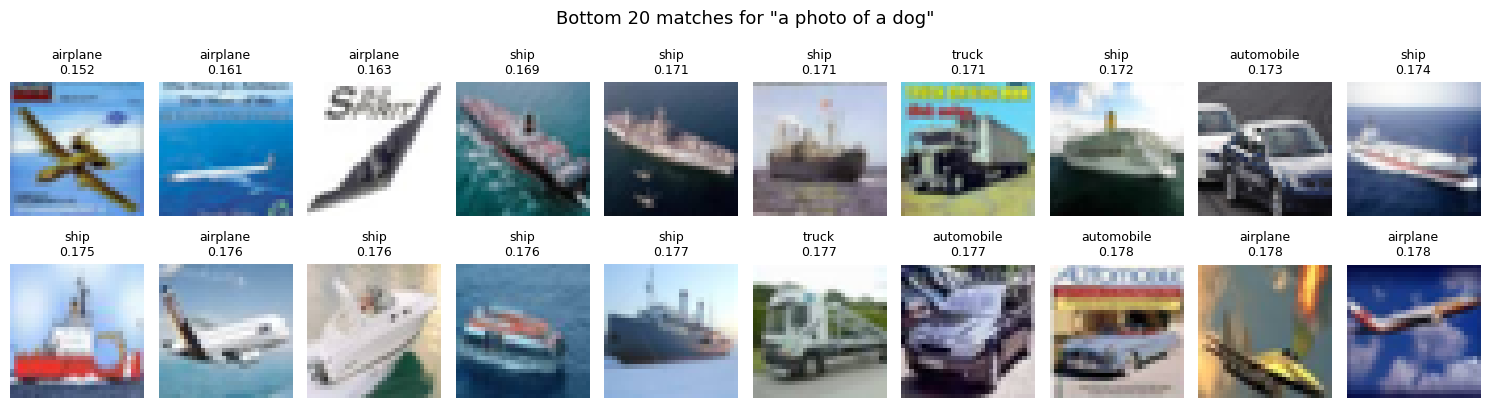

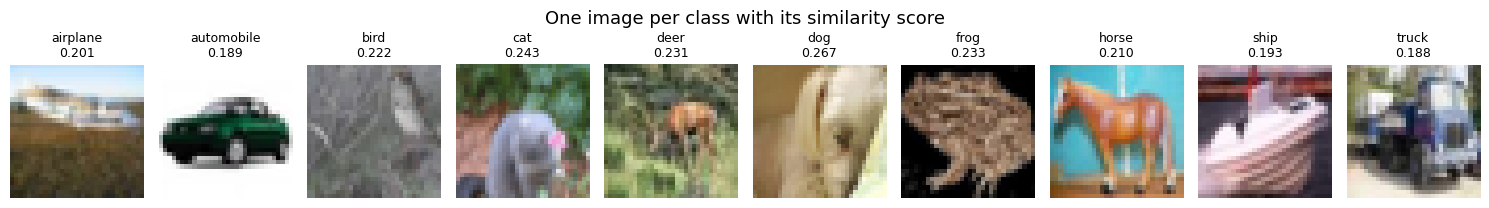

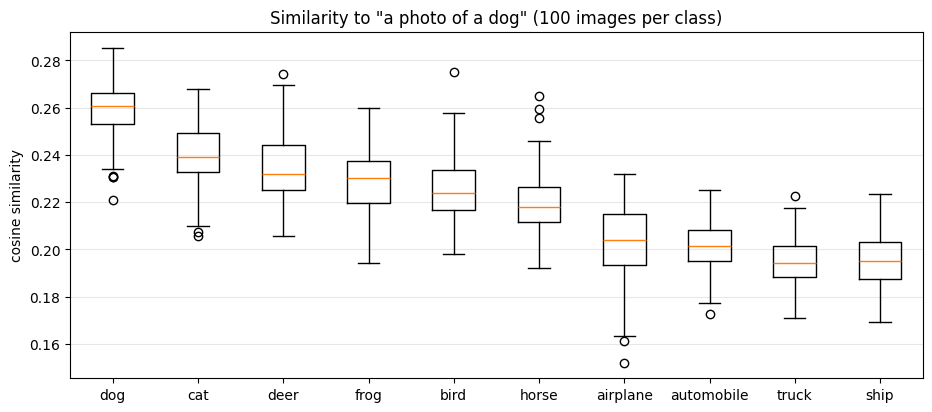

In [7]:
import matplotlib.pyplot as plt

def show_grid(indices, title, ncols=10):
    rows = int(np.ceil(len(indices) / ncols))
    fig, axes = plt.subplots(rows, ncols, figsize=(ncols * 1.5, rows * 2.2))
    for ax, i in zip(np.array(axes).ravel(), indices):
        ax.imshow(images[i])
        ax.set_title(f"{classes[labels[i]]}\n{similarities[i]:.3f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

order = np.argsort(similarities)[::-1]

# 1. Top 20 and bottom 20 images with their scores
show_grid(order[:20], f'Top 20 matches for "{caption}"')
show_grid(order[-20:][::-1], f'Bottom 20 matches for "{caption}"')

# 2. One random image from each class, with its score
rng = np.random.default_rng(SEED)
one_each = [rng.choice(np.where(labels == c)[0]) for c in range(10)]
show_grid(one_each, "One image per class with its similarity score")

# 3. Box plot of the score distribution for each class
class_order = per_class.index.tolist()   # sorted by mean, from Step 4
plt.figure(figsize=(11, 4.5))
plt.boxplot([df[df["class"] == c]["similarity"] for c in class_order], tick_labels=class_order)
plt.ylabel("cosine similarity")
plt.title(f'Similarity to "{caption}" (100 images per class)')
plt.grid(axis="y", alpha=0.3)
plt.show()

## Findings
**Setup:** CLIP ViT-B/32 compared "a photo of a dog" with 1,000 CIFAR-10 images (100 per class) using cosine similarity.

**Results:** Dogs scored highest (0.259), then other animals (0.220–0.239); vehicles scored lowest (0.195–0.204).

**Images:** 18 of the top 20 were dogs; the other two were dog-like animals. The bottom 20 were all vehicles.

**Limitations:** Scores span a narrow range (0.15–0.29), classes overlap, and 32×32 images are blurry.

**Conclusion:** CLIP ranks dogs highest and separates animals from vehicles, but one caption gives a ranking, not a classifier.

Part 2 (zero-shot CIFAR-10)

In [8]:
all_images = [test_set[i][0] for i in range(len(test_set))]
all_image_emb = get_image_embeddings(all_images)
print(all_image_emb.shape)

torch.Size([10000, 512])


In [9]:
class_captions = [f"a photo of a {c}" for c in classes]
text_emb = get_text_embeddings(class_captions)

scores = all_image_emb @ text_emb.T
preds = scores.argmax(dim=1).cpu().numpy()

accuracy = (preds == all_labels).mean()
print(f"Overall zero-shot accuracy: {accuracy:.2%}")

Overall zero-shot accuracy: 88.80%


In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, preds)
per_class_acc = cm.diagonal() / cm.sum(axis=1)

for c, acc in sorted(zip(classes, per_class_acc), key=lambda x: -x[1]):
    print(f"{c:12s} {acc:.2%}")

automobile   97.60%
horse        97.60%
ship         95.50%
airplane     90.10%
truck        90.10%
bird         88.80%
dog          88.40%
cat          86.00%
frog         77.40%
deer         76.50%


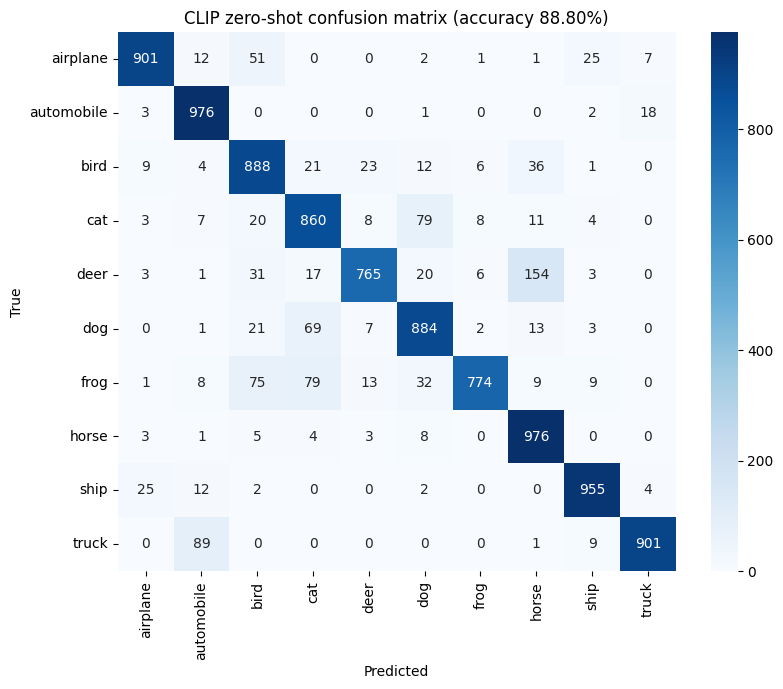

In [11]:
import seaborn as sns

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"CLIP zero-shot confusion matrix (accuracy {accuracy:.2%})")
plt.show()

Part 2 Findings

Accuracy: 88.80% zero-shot on 10,000 test images, with no training.

Per class: Best were automobile and horse (97.6%); worst were deer (76.5%) and frog (77.4%).

Confusions: deer to horse, truck to automobile, cat and dog. All are visually similar pairs.

Conclusion: CLIP classifies CIFAR-10 well without training. Errors come from similar classes and the blurry 32x32 images.